# Annotation Experiment Analysis
This notebook evaluates the annotation experiment results from `annotated_data` ($N=216$ samples).
It provides:
1. **Annotation Workflow Overview** (sample counts, discussions, expert escalations)
2. **Inter-Annotator Agreement** (Percentage Agreement vs. Bennett's $S$ before and after discussion)
3. **Offensiveness Prevalence by Topic** (Before Annotator Decision vs. After Expert Decision)


In [1]:
import os
import glob
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# arbiter_analysis has functions to load and read data exported from Arbiter. 
# It can be installed from https://example.invalid/course-tools.git
import arbiter_analysis
from arbiter_analysis.load import user_label as _orig_user_label, discussion_label as _orig_discussion_label

# Wrapper for user_label and discussion_label:
# In annotated_data the label was recorded as 'Offensiveness' (with capital O), whereas in example_data it was 'offensive'.
# This wrapper handles both so it works 100% on the GPU cluster and locally.
def user_label(labels_list, cur_ann, label="Offensiveness"):
    if not isinstance(labels_list, list):
        return np.nan
    for entry in labels_list:
        if entry.get("user") == cur_ann or cur_ann in entry.get("user", ""):
            lbls = entry.get("labels", [])
            is_pos = (len(lbls) > 0) and any("offensiv" in str(l).lower() for l in lbls)
            return 1 if is_pos else 0
    return np.nan

def discussion_label(row, cur_ann, label="Offensiveness"):
    disc = row.get("labels_discussion", [])
    val = user_label(disc, cur_ann, label=label)
    if not np.isnan(val):
        return val
    ann = row.get("labels_annotation", [])
    return user_label(ann, cur_ann, label=label)

import irrCAC
from irrCAC.raw import CAC

# Plot styling configuration
plt.rcParams.update({
    "font.size": 11,
    "axes.labelsize": 12,
    "axes.titlesize": 13,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "figure.titlesize": 14
})

# Robust path resolution for GPU workstation and local environments
candidate_base_paths = [
    'scratch/bsem-group/group_01/annotation_experiment/',
    '/scratch/bsem-group/group_01/annotation_experiment/',
    '/scratch/users/instructor/bsem-ws26-starter/annotation_experiment/',
    './',
    'annotation_experiment/'
]

path = '../'
for p in candidate_base_paths:
    if os.path.exists(os.path.join(p, 'annotated_data')):
        path = p
        break

print(f"Base path resolved to: {path}")


Base path resolved to: annotation_experiment/


In [2]:
# replace with your data
batch_path = os.path.join(path, "annotated_data/") if os.path.exists(os.path.join(path, "annotated_data/")) else "annotated_data/"
df = arbiter_analysis.load.annotations(batch_path=batch_path)
df.head(3)


,text_id,text,labels_annotation,labels_discussion,messages_discussion,labels_expert,batch_number,batch_annotators,batch_experts
0,137,[Covid-19]: My heart skipped a little at the i...,"[{'user': 'group1_annotator1', 'labels': [], '...",[],[],[],1,"[group1_annotator1, group1_annotator2]",[group1_expert]
1,138,[BLM]: #Burial #Pandemic #SocialDistancing #Co...,"[{'user': 'group1_annotator1', 'labels': [], '...",[],[],[],1,"[group1_annotator1, group1_annotator2]",[group1_expert]
2,139,[Elections2020]: #MAGA chuds that have the men...,"[{'user': 'group1_annotator1', 'labels': [], '...","[{'user': 'group1_annotator1', 'labels': ['Off...","[{'user': 'group1_annotator2', 'at': '2026-10-...",[],1,"[group1_annotator1, group1_annotator2]",[group1_expert]


## 1. Workflow Statistics Overview

In [3]:
n = df.shape[0]
n_batches = len(df.batch_number.unique())
n_discussions = sum(df['labels_discussion'].apply(lambda x: len(x)) > 0)
n_experts = sum(df['labels_expert'].apply(lambda x: len(x)) > 0)

print("Number of annotated samples:", n)
print("Number of batches:", n_batches)
print("Number of discussions:", n_discussions)
print("Number of expert decisions:", n_experts)


Number of annotated samples: 216
Number of batches: 7
Number of discussions: 28
Number of expert decisions: 4


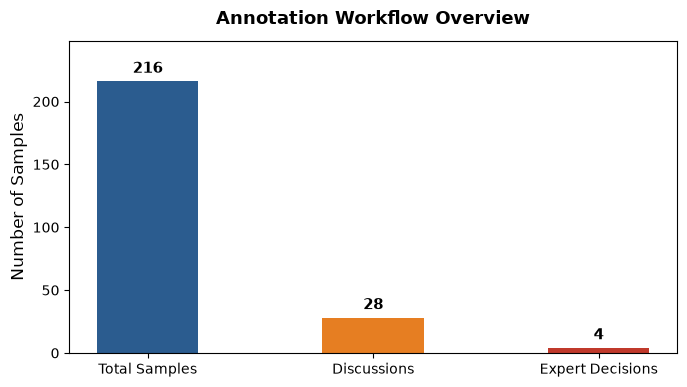

In [4]:
# plot workflow statistics
fig, ax = plt.subplots(figsize=(7, 4))
metrics = ["Total Samples", "Discussions", "Expert Decisions"]
counts = [n, n_discussions, n_experts]
colors = ["#2b5c8f", "#e67e22", "#c0392b"]

bars = ax.bar(metrics, counts, color=colors, width=0.45)
ax.set_ylabel("Number of Samples")
ax.set_title("Annotation Workflow Overview", fontweight="bold", pad=12)
ax.set_ylim(0, max(counts) * 1.15)

for bar in bars:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width() / 2.0, yval + 4, f"{int(yval)}", ha="center", va="bottom", fontweight="bold")

plt.tight_layout()
plt.show()


## 2. Inter-Annotator Agreement: PA vs. Bennett's S

In [5]:
# create four new columns: 2 annotators (annotator1 and annotator2) x 2 stages (before and after discussion)
for cur_stage in ["before", "after"]:
    for cur_ann in ["group1_annotator1", "group1_annotator2"]:
        if cur_stage == "before":
            df[cur_stage + "_" + cur_ann] = df["labels_annotation"].apply(lambda e: user_label(e, cur_ann))
        elif cur_stage == "after":
            df[cur_stage + "_" + cur_ann] = df.apply(lambda r: discussion_label(r, cur_ann), axis=1)

# compute percentage agreement
before_pa = sum(df["before_group1_annotator1"] == df["before_group1_annotator2"]) / df.shape[0]
after_pa = sum(df["after_group1_annotator1"] == df["after_group1_annotator2"]) / df.shape[0]

# Chance-corrected agreement metric: Bennett, Alpert, and Goldstein’s S
# In irrCAC, Bennett's S is computed by the Brennan-Prediger (bp) method (for k=2, S = 2*Po - 1)
cac_before = CAC(df[["before_group1_annotator1", "before_group1_annotator2"]])
cac_after = CAC(df[["after_group1_annotator1", "after_group1_annotator2"]])

before_s = cac_before.bp()["est"]["coefficient_value"]
after_s = cac_after.bp()["est"]["coefficient_value"]

print(f"Percentage Agreement Before: {before_pa:.4f} | Bennett's S Before: {before_s:.4f}")
print(f"Percentage Agreement After:  {after_pa:.4f} | Bennett's S After:  {after_s:.4f}")


Percentage Agreement Before: 0.8704 | Bennett's S Before: 0.7407
Percentage Agreement After:  0.9815 | Bennett's S After:  0.9630


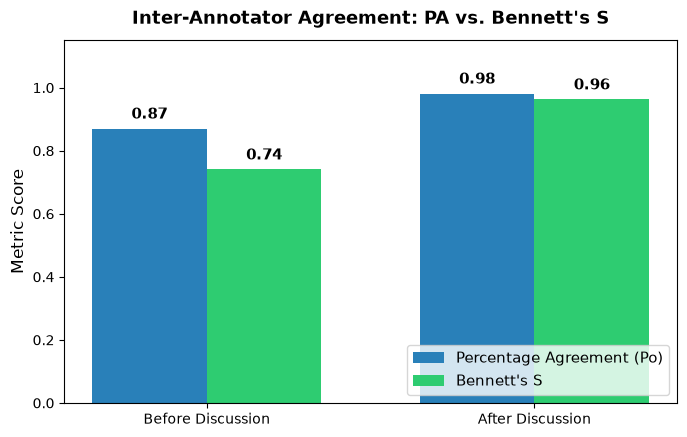

In [6]:
# Plot Percentage Agreement vs Bennett's S (Chance-Corrected Agreement)
fig, ax = plt.subplots(figsize=(7, 4.5))
x = np.arange(2)
width = 0.35

bars_pa = ax.bar(x - width/2, [before_pa, after_pa], width, label="Percentage Agreement (Po)", color="#2980b9")
bars_s = ax.bar(x + width/2, [before_s, after_s], width, label="Bennett's S", color="#2ecc71")

ax.set_ylabel("Metric Score")
ax.set_title("Inter-Annotator Agreement: PA vs. Bennett's S", fontweight="bold", pad=12)
ax.set_xticks(x)
ax.set_xticklabels(["Before Discussion", "After Discussion"])
ax.set_ylim(0, 1.15)
ax.legend(loc="lower right")

for bar in list(bars_pa) + list(bars_s):
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width() / 2.0, height + 0.02, f"{height:.2f}", ha="center", va="bottom", fontweight="bold")

plt.tight_layout()
plt.show()


## 3. Offensiveness Prevalence by Topic

In [7]:
# Extract topic from tweet text prefix
def get_topic(text):
    if "[Covid-19]" in text:
        return "Covid-19"
    elif "[Elections2020]" in text:
        return "Elections2020"
    elif "[BLM]" in text:
        return "BLM"
    return "Other"

df["topic"] = df["text"].apply(get_topic)

# Extract the final label
# the final label is the expert label, if there is one, if there is no expert label, it is the label after discussion, 
# if there is no label after discussion, it is the annotation label
def final_label(row, annotator="group1_annotator1", label="Offensiveness"):
    expert = user_label(row["labels_expert"], "group1_expert", label)
    if np.isnan(expert):
        expert = user_label(row["labels_expert"], "expert", label)
    if not np.isnan(expert):
        return expert
    disc = discussion_label(row, annotator, label)
    if not np.isnan(disc):
        return disc
    return user_label(row["labels_annotation"], annotator, label)

df["final_label"] = df.apply(final_label, axis=1)


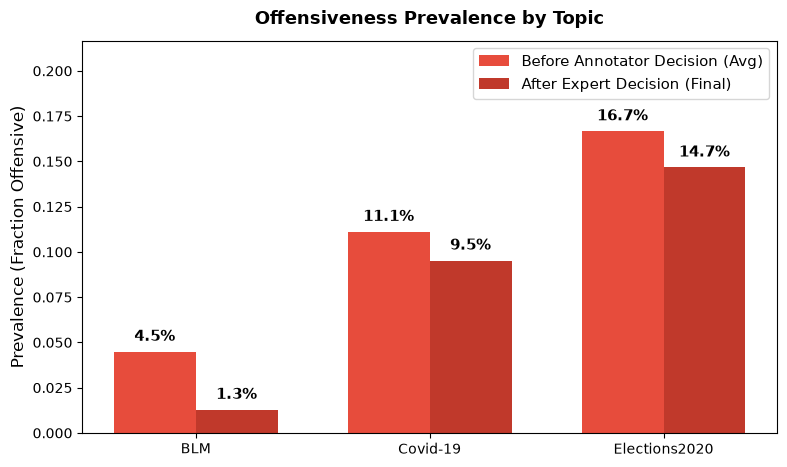

In [8]:
# Plot Offensiveness Prevalence by Topic: Before Annotator Decision vs. After Expert Decision
topics = ["BLM", "Covid-19", "Elections2020"]
x = np.arange(len(topics))
width = 0.35

prev_before = []
prev_expert = []

for t in topics:
    sub = df[df["topic"] == t]
    p_b = (sub["before_group1_annotator1"].mean() + sub["before_group1_annotator2"].mean()) / 2.0
    p_e = sub["final_label"].mean()
    prev_before.append(p_b)
    prev_expert.append(p_e)

fig, ax = plt.subplots(figsize=(8, 4.8))
bars_b = ax.bar(x - width/2, prev_before, width, label="Before Annotator Decision (Avg)", color="#e74c3c")
bars_e = ax.bar(x + width/2, prev_expert, width, label="After Expert Decision (Final)", color="#c0392b")

ax.set_ylabel("Prevalence (Fraction Offensive)")
ax.set_title("Offensiveness Prevalence by Topic", fontweight="bold", pad=12)
ax.set_xticks(x)
ax.set_xticklabels(topics)
ax.set_ylim(0, max(prev_before) * 1.30)
ax.legend(loc="upper right")

for bar in list(bars_b) + list(bars_e):
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width() / 2.0, height + 0.004, f"{height:.1%}", ha="center", va="bottom", fontweight="bold")

plt.tight_layout()
plt.show()
